# FrutaCheck: control de calidad de fruta con SVM. Notebook de entrenamiento

**Inteligencia Artificial I · Actividad 3 · Grupo 1**
**Integrantes:** Jhon Alejandro Velasco García · Yesid Esteban Avendaño Barbosa · Keiner Astos
**Algoritmo asignado:** Support Vector Machines (SVM)

Este notebook entrena el modelo que usa la aplicación web FrutaCheck: un clasificador SVM que, a partir de una foto, dice qué fruta es y si está **fresca o podrida**. Cubre carga y exploración de datos, EDA, preprocesamiento, entrenamiento con búsqueda de hiperparámetros, evaluación y serialización del modelo.

## 1. Necesidad, problema y datos

**Necesidad.** En Colombia se pierden o desperdician 9,76 millones de toneladas de alimentos al año, el 34 % de lo disponible, y las frutas y verduras concentran cerca de 6,1 millones de toneladas [DNP, 2016]. En fruterías, tiendas de barrio y plazas de mercado la calidad se revisa a ojo: una fruta podrida que se queda en el exhibidor acelera el daño de las vecinas, y un lote malo que se recibe sin revisar es dinero perdido. FrutaCheck ayuda a **detectar a tiempo la fruta podrida**, sacarla del exhibidor y decidir si se recibe un lote del proveedor.

**Problema de machine learning.** Clasificación multiclase de imágenes: cada foto pertenece a una clase `<fruta>_<estado>` (por ejemplo `manzana_fresca` o `banano_podrido`). De la clase se obtienen la fruta y el estado.

**Datos.** *Fresh and Rotten Fruits Dataset for Machine-Based Evaluation of Fruit Quality* [Sultana, Jahan y Uddin, 2022], Mendeley Data, licencia CC BY 4.0. Son fotos **reales** tomadas en fruterías y en campo, clasificadas como frescas o podridas por un experto de un instituto agrícola. Se usan solo las imágenes **originales** (no las aumentadas que trae el dataset). El script `src/preparar_datos.py` las reduce a 256 píxeles por el lado corto y las guarda en `data/raw/<clase>/`.

**Por qué SVM.** Cada imagen se describe con cientos de características (color, textura y forma). Un SVM busca la frontera que separa las clases con el **mayor margen** posible y, con el kernel RBF, puede separar clases que no son linealmente separables. Funciona bien con muchas variables y pocos miles de ejemplos, que es justo este caso.

**Restricción de la actividad.** No se usan modelos pre-entrenados ni redes neuronales: las características se calculan con fórmulas fijas y el SVM se entrena desde cero.

In [1]:
import hashlib
import json
import sys
import time
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from PIL import Image, ImageOps
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src.predict import interpretar_clase, nombre_clase
from src.preprocessing import (cargar_imagen, extraer_caracteristicas, listar_imagenes,
                               nombres_caracteristicas, normalizar_imagen)

SEMILLA = 42
CARPETA_RAW = RAIZ / "data" / "raw"
CARPETA_PROCESADA = RAIZ / "data" / "processed"
CARPETA_MODELOS = RAIZ / "models"
CARPETA_PROCESADA.mkdir(parents=True, exist_ok=True)
CARPETA_MODELOS.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
print(f"[INFO] Raiz del proyecto: {RAIZ}")
print(f"[INFO] scikit-learn {sklearn.__version__}")

[INFO] Raiz del proyecto: D:\JHON\Uni\inteligencia_artificial_trabajoU
[INFO] scikit-learn 1.6.1


## 2. Carga y exploración de datos

Se recorre `data/raw/<clase>/` y se arma una tabla con una fila por imagen: ruta, clase, fruta, estado, tamaño y huella (hash) del archivo para detectar duplicados exactos.

In [2]:
registros = listar_imagenes(CARPETA_RAW)
if not registros:
    raise SystemExit("[ERROR] No hay imagenes en data/raw/<clase>/. Ejecute src/preparar_datos.py")

filas = []
for ruta, clase in registros:
    with Image.open(ruta) as img:
        ancho, alto = img.size
    fruta, estado = interpretar_clase(clase)
    filas.append({"ruta": ruta.relative_to(RAIZ).as_posix(), "clase": clase, "fruta": fruta, "estado": estado,
                  "ancho": ancho, "alto": alto, "hash": hashlib.md5(ruta.read_bytes()).hexdigest()})
df = pd.DataFrame(filas)
df.info()
display(df.describe(include="all"))
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3200 entries, 0 to 3199
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   ruta    3200 non-null   object
 1   clase   3200 non-null   object
 2   fruta   3200 non-null   object
 3   estado  3200 non-null   object
 4   ancho   3200 non-null   int64 
 5   alto    3200 non-null   int64 
 6   hash    3200 non-null   object
dtypes: int64(2), object(5)
memory usage: 175.1+ KB


,ruta,clase,fruta,estado,ancho,alto,hash
count,3200,3200,3200,3200,3200.000000,3200.000000,3200
unique,3200,16,8,2,NaN,NaN,3193
top,data/raw/uva_podrida/uva_podrida_0183.jpg,azufaifa_fresca,azufaifa,fresca,NaN,NaN,e8c4d2ff13c7d5bd7d5b1a0bcfa6f8e9
freq,1,200,400,1600,NaN,NaN,2
mean,NaN,NaN,NaN,NaN,293.216250,277.202500,NaN
std,NaN,NaN,NaN,NaN,47.220408,41.918649,NaN
min,NaN,NaN,NaN,NaN,251.000000,256.000000,NaN
25%,NaN,NaN,NaN,NaN,256.000000,256.000000,NaN
50%,NaN,NaN,NaN,NaN,273.000000,256.000000,NaN
75%,NaN,NaN,NaN,NaN,324.000000,279.000000,NaN


,ruta,clase,fruta,estado,ancho,alto,hash
0,data/raw/azufaifa_fresca/azufaifa_fresca_0000.jpg,azufaifa_fresca,azufaifa,fresca,277,256,e56b981bcde13af26deefc8686f7370d
1,data/raw/azufaifa_fresca/azufaifa_fresca_0001.jpg,azufaifa_fresca,azufaifa,fresca,289,256,24368c51001e074a3d3938c8f357370d
2,data/raw/azufaifa_fresca/azufaifa_fresca_0002.jpg,azufaifa_fresca,azufaifa,fresca,256,336,42bb0dc35b51d68ee8c7e89b8fb48cb9
3,data/raw/azufaifa_fresca/azufaifa_fresca_0003.jpg,azufaifa_fresca,azufaifa,fresca,256,341,d09f990a6d0a8c6a2239beb46d4963e6
4,data/raw/azufaifa_fresca/azufaifa_fresca_0004.jpg,azufaifa_fresca,azufaifa,fresca,281,256,6630da9219d9e9fb1e2d5ba284a5bc6c


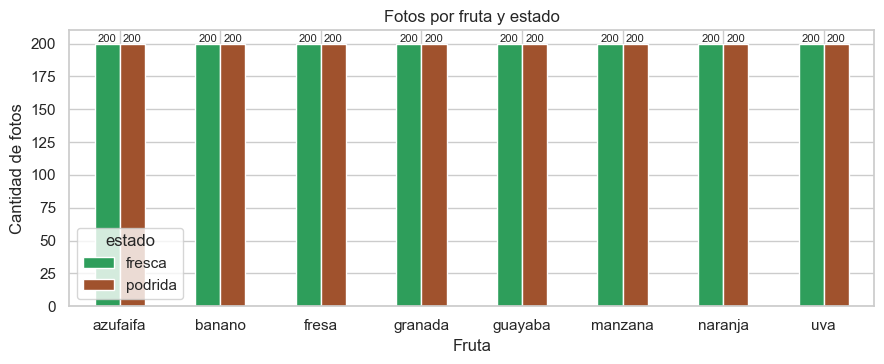

[INFO] 3200 imagenes, 16 clases, 8 frutas
[INFO] Frescas: 1600 | Podridas: 1600


estado,fresca,podrida
fruta,,
azufaifa,200,200
banano,200,200
fresa,200,200
granada,200,200
guayaba,200,200
manzana,200,200
naranja,200,200
uva,200,200


In [3]:
conteo = pd.crosstab(df["fruta"], df["estado"])
ax = conteo.plot(kind="bar", figsize=(9, 3.8), color={"fresca": "#2E9E5B", "podrida": "#A0522D"}, rot=0)
for contenedor in ax.containers:
    ax.bar_label(contenedor, fontsize=8)
ax.set(title="Fotos por fruta y estado", xlabel="Fruta", ylabel="Cantidad de fotos")
plt.tight_layout(); plt.show()
print(f"[INFO] {len(df)} imagenes, {df['clase'].nunique()} clases, {df['fruta'].nunique()} frutas")
print(f"[INFO] Frescas: {(df['estado'] == 'fresca').sum()} | Podridas: {(df['estado'] == 'podrida').sum()}")
conteo

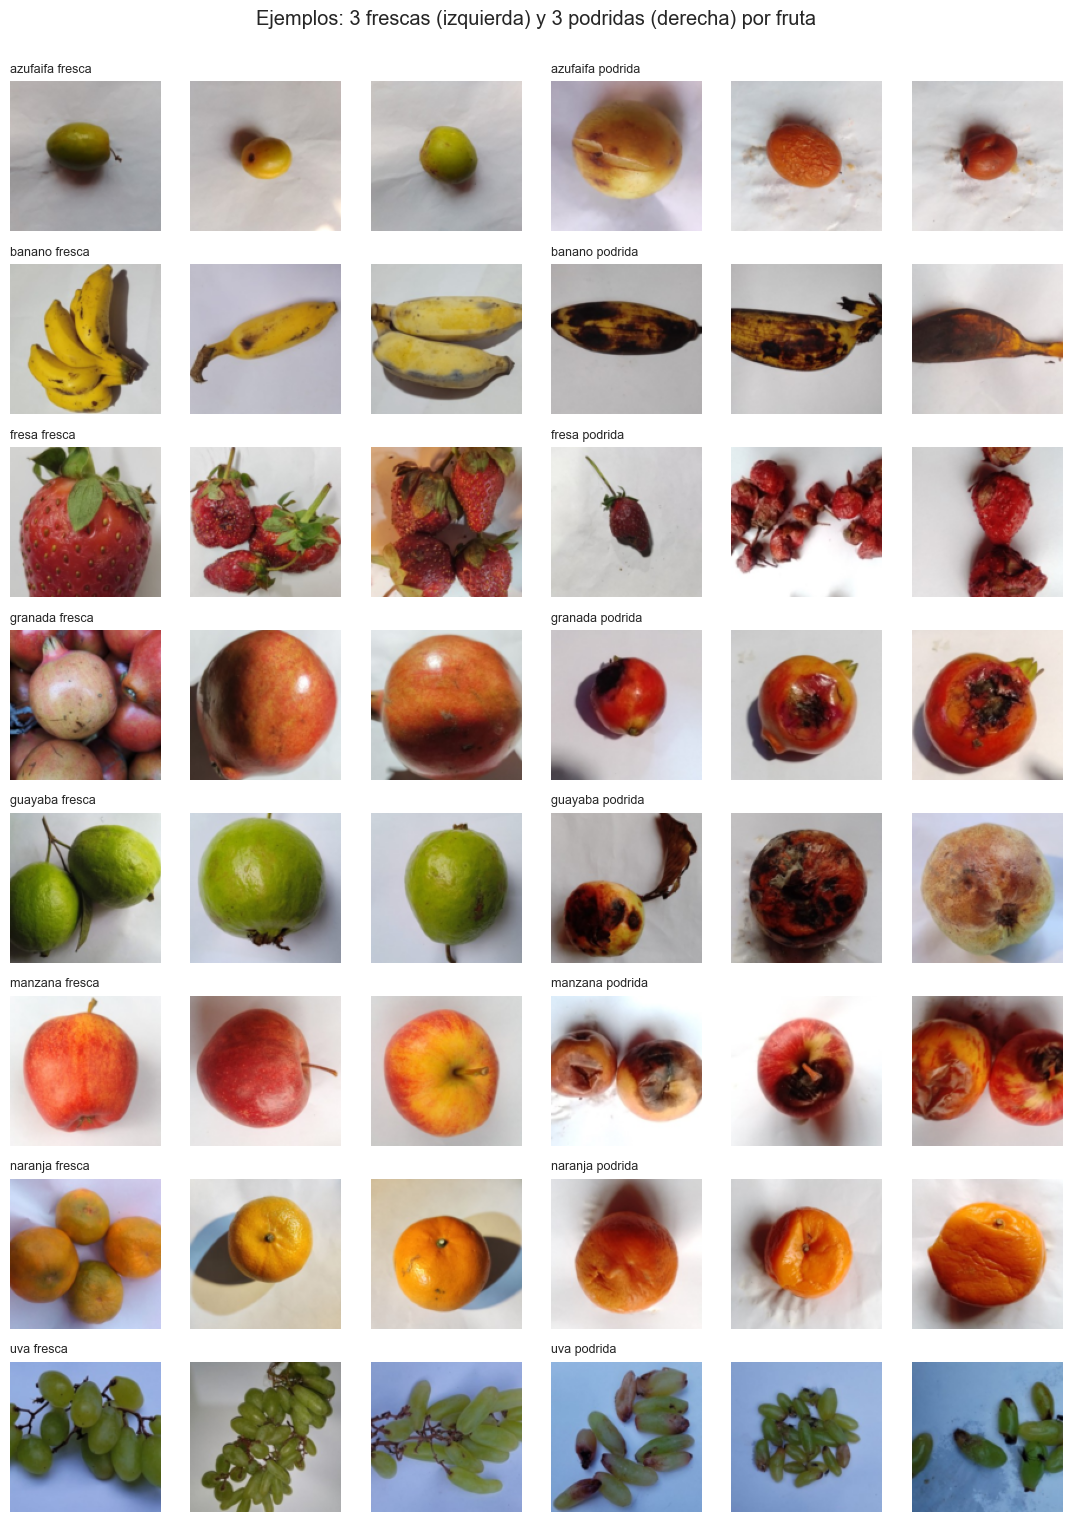

In [4]:
frutas = sorted(df["fruta"].unique())
fig, ejes = plt.subplots(len(frutas), 6, figsize=(11, 1.9 * len(frutas)))
ejes = np.atleast_2d(ejes)
for fila, fruta in enumerate(frutas):
    for bloque, estado in enumerate(["fresca", "podrida"]):
        sub = df[(df["fruta"] == fruta) & (df["estado"] == estado)]
        muestra = sub.sample(min(3, len(sub)), random_state=SEMILLA)
        for k in range(3):
            eje = ejes[fila, bloque * 3 + k]
            eje.axis("off")
            if k < len(muestra):
                eje.imshow(normalizar_imagen(cargar_imagen(RAIZ / muestra.iloc[k]["ruta"])))
            if k == 0:
                eje.set_title(f"{fruta} {estado}", loc="left", fontsize=9)
plt.suptitle("Ejemplos: 3 frescas (izquierda) y 3 podridas (derecha) por fruta", y=1.0)
plt.tight_layout(); plt.show()

## 3. Análisis exploratorio (EDA)

### 3.1 Extracción de características

El SVM no recibe píxeles sueltos sino un vector que resume cada foto (función `extraer_caracteristicas` de `src/preprocessing.py`). Antes de calcularlo, cada foto se recorta al cuadrado central y se reduce a 128 × 128 píxeles.

| Bloque | Qué describe | Por qué sirve aquí | Valores |
|---|---|---|---|
| Histograma H (tono) | Qué colores tiene la fruta | Distingue la fruta y el pardeamiento | 16 |
| Histograma S (saturación) | Qué tan vivos son los colores | La fruta podrida pierde color | 8 |
| Histograma V (brillo) | Qué tan clara u oscura es | Manchas oscuras de pudrición | 8 |
| LBP uniforme | Textura local de la cáscara | Moho, arrugas y manchas | 10 |
| HOG | Dirección de los bordes por zona | Forma de la fruta | 1.764 |

In [5]:
inicio = time.time()
X_total = np.vstack([extraer_caracteristicas(cargar_imagen(RAIZ / r)) for r in df["ruta"]])
columnas = nombres_caracteristicas()
caracteristicas = pd.DataFrame(X_total, columns=columnas)
caracteristicas.insert(0, "clase", df["clase"].values)
caracteristicas.insert(0, "ruta", df["ruta"].values)
caracteristicas.to_csv(CARPETA_PROCESADA / "caracteristicas.csv", index=False)
print(f"[OK] Matriz de caracteristicas: {X_total.shape[0]} imagenes x {X_total.shape[1]} variables "
      f"({time.time() - inicio:.1f} s)")
print("[OK] Guardada en data/processed/caracteristicas.csv")

[OK] Matriz de caracteristicas: 3200 imagenes x 1806 variables (22.8 s)
[OK] Guardada en data/processed/caracteristicas.csv


### 3.2 Valores nulos y duplicados

Además de los duplicados exactos (mismo archivo), se buscan **casi duplicados**: la misma fruta fotografiada dos veces casi igual. Se calcula una huella perceptual (*dHash* de 64 bits) y se unen las fotos de la misma clase cuya huella difiere en pocos bits. Esos grupos se usan después para que una foto y su casi gemela no queden una en entrenamiento y otra en prueba (*data leakage*).

In [6]:
def dhash(ruta, lado=8):
    gris = np.asarray(normalizar_imagen(cargar_imagen(RAIZ / ruta)).convert("L").resize((lado + 1, lado)),
                      dtype=np.int16)
    return (gris[:, 1:] > gris[:, :-1]).flatten()

huellas = np.array([dhash(r) for r in df["ruta"]])
UMBRAL_BITS = 6
padre = list(range(len(df)))

def raiz(i):
    while padre[i] != i:
        padre[i] = padre[padre[i]]
        i = padre[i]
    return i

for clase, indices in df.groupby("clase").indices.items():
    h = huellas[indices]
    distancias = (h[:, None, :] != h[None, :, :]).sum(axis=2)
    for a, b in zip(*np.where(np.triu(distancias <= UMBRAL_BITS, k=1))):
        padre[raiz(indices[a])] = raiz(indices[b])
df["grupo"] = [f"g{raiz(i)}" for i in range(len(df))]

nulos = int(caracteristicas[columnas].isna().sum().sum())
infinitos = int(np.isinf(X_total).sum())
duplicados = int(df["hash"].duplicated().sum())
tam_grupos = df["grupo"].value_counts()
print(f"[INFO] Valores nulos: {nulos} | infinitos: {infinitos} | duplicados exactos: {duplicados}")
print(f"[INFO] Grupos de casi duplicados (dHash <= {UMBRAL_BITS} bits): {(tam_grupos > 1).sum()} grupos "
      f"con {tam_grupos[tam_grupos > 1].sum()} fotos; {len(tam_grupos)} grupos en total")

[INFO] Valores nulos: 0 | infinitos: 0 | duplicados exactos: 7
[INFO] Grupos de casi duplicados (dHash <= 6 bits): 162 grupos con 493 fotos; 2869 grupos en total


### 3.3 Color y brillo: frescas frente a podridas

Si el modelo puede separar frescas de podridas por color, la fruta podrida debería verse más oscura y menos saturada. Se compara el brillo medio (V) y la saturación media (S) de cada foto por fruta y estado.

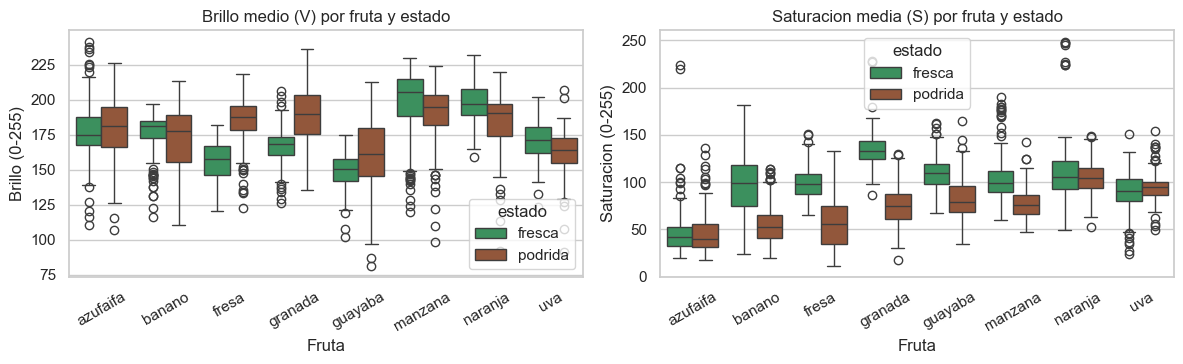

,brillo,saturacion
estado,,
fresca,174.399994,99.400002
podrida,178.199997,74.000000


In [7]:
brillo, saturacion = [], []
for r in df["ruta"]:
    hsv = np.asarray(normalizar_imagen(cargar_imagen(RAIZ / r)).convert("HSV"), dtype=np.float32)
    saturacion.append(hsv[:, :, 1].mean())
    brillo.append(hsv[:, :, 2].mean())
df["brillo"], df["saturacion"] = brillo, saturacion

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
paleta = {"fresca": "#2E9E5B", "podrida": "#A0522D"}
sns.boxplot(data=df, x="fruta", y="brillo", hue="estado", palette=paleta, ax=ejes[0])
ejes[0].set(title="Brillo medio (V) por fruta y estado", xlabel="Fruta", ylabel="Brillo (0-255)")
sns.boxplot(data=df, x="fruta", y="saturacion", hue="estado", palette=paleta, ax=ejes[1])
ejes[1].set(title="Saturacion media (S) por fruta y estado", xlabel="Fruta", ylabel="Saturacion (0-255)")
for eje in ejes:
    eje.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
df.groupby("estado")[["brillo", "saturacion"]].mean().round(1)

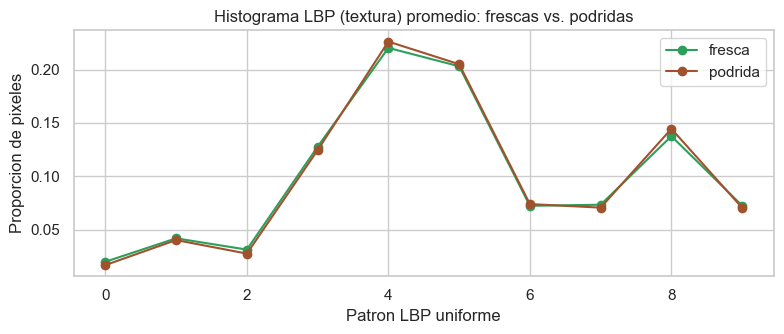

In [8]:
cols_lbp = [c for c in columnas if c.startswith("lbp_")]
promedio_lbp = caracteristicas.assign(estado=df["estado"].values).groupby("estado")[cols_lbp].mean()
fig, ax = plt.subplots(figsize=(8, 3.5))
for estado, fila in promedio_lbp.iterrows():
    ax.plot(range(len(cols_lbp)), fila.values, marker="o", label=estado, color=paleta[estado])
ax.set(title="Histograma LBP (textura) promedio: frescas vs. podridas", xlabel="Patron LBP uniforme",
       ylabel="Proporcion de pixeles")
ax.legend(); plt.tight_layout(); plt.show()

### 3.4 Correlaciones

Correlación entre las variables de color y textura (42). Bloques muy correlacionados indican información redundante; el SVM con estandarización lo tolera bien, pero es útil conocerlo.

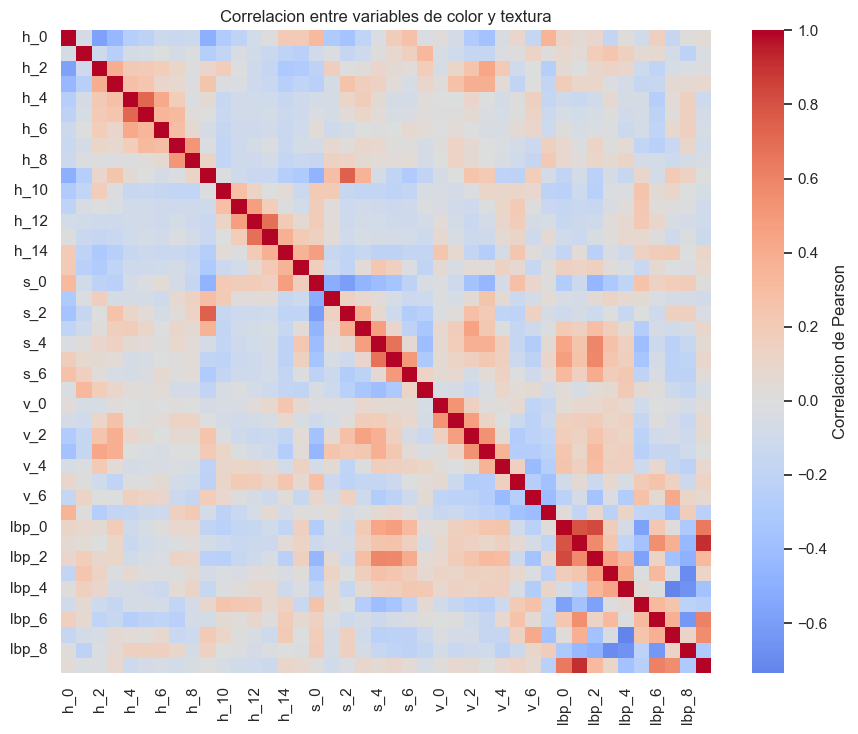

In [9]:
cols_ct = [c for c in columnas if not c.startswith("hog_")]
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(caracteristicas[cols_ct].corr(), cmap="coolwarm", center=0, ax=ax,
            cbar_kws={"label": "Correlacion de Pearson"})
ax.set_title("Correlacion entre variables de color y textura")
plt.tight_layout(); plt.show()

### 3.5 Outliers

Fotos con brillo muy distinto al de su clase (|z| > 3) pueden estar sobreexpuestas o muy oscuras. Se revisan a ojo antes de decidir si se quitan.

[INFO] Fotos con brillo atipico (|z| > 3): 30


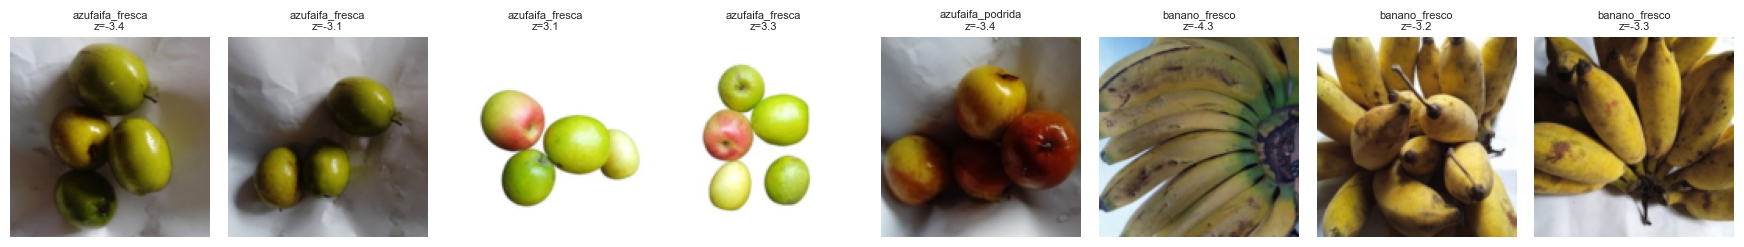

,ruta,clase,brillo,z_brillo
169,data/raw/azufaifa_fresca/azufaifa_fresca_0169.jpg,azufaifa_fresca,110.509460,-3.374446
170,data/raw/azufaifa_fresca/azufaifa_fresca_0170.jpg,azufaifa_fresca,116.371643,-3.077686
172,data/raw/azufaifa_fresca/azufaifa_fresca_0172.jpg,azufaifa_fresca,237.868652,3.072829
177,data/raw/azufaifa_fresca/azufaifa_fresca_0177.jpg,azufaifa_fresca,241.646851,3.264092
345,data/raw/azufaifa_podrida/azufaifa_podrida_014...,azufaifa_podrida,106.988037,-3.383873
401,data/raw/banano_fresco/banano_fresco_0001.jpg,banano_fresco,116.519714,-4.334854
499,data/raw/banano_fresco/banano_fresco_0099.jpg,banano_fresco,131.606018,-3.248506
501,data/raw/banano_fresco/banano_fresco_0101.jpg,banano_fresco,131.429932,-3.261186
510,data/raw/banano_fresco/banano_fresco_0110.jpg,banano_fresco,122.967712,-3.870541
1139,data/raw/fresa_podrida/fresa_podrida_0139.jpg,fresa_podrida,122.592468,-3.888116


In [10]:
df["z_brillo"] = df.groupby("clase")["brillo"].transform(lambda s: (s - s.mean()) / (s.std(ddof=0) + 1e-9))
atipicas = df[df["z_brillo"].abs() > 3]
print(f"[INFO] Fotos con brillo atipico (|z| > 3): {len(atipicas)}")
if len(atipicas):
    n = min(8, len(atipicas))
    fig, ejes = plt.subplots(1, n, figsize=(2.2 * n, 2.6))
    for eje, (_, fila) in zip(np.atleast_1d(ejes), atipicas.head(n).iterrows()):
        eje.imshow(normalizar_imagen(cargar_imagen(RAIZ / fila["ruta"])))
        eje.set_title(f"{fila['clase']}\nz={fila['z_brillo']:.1f}", fontsize=8)
        eje.axis("off")
    plt.tight_layout(); plt.show()
atipicas[["ruta", "clase", "brillo", "z_brillo"]]

**Decisión sobre outliers:** las fotos atípicas por brillo se **conservan**. En una frutería real la luz también varía (sol, bombillo, sombra) y el modelo debe aprender a manejarlo; solo se quitarían si la foto no mostrara la fruta.

## 4. Preprocesamiento

1. **Limpieza:** se quitan duplicados exactos (mismo hash).
2. **Codificación:** la clase es texto y scikit-learn la acepta directamente en `SVC`; no hay otras variables categóricas.
3. **División train/test por grupos:** las fotos casi duplicadas (sección 3.2) forman un grupo, y cada grupo completo va a entrenamiento o a prueba. Así se evita *data leakage*. La división es aproximadamente 80 % / 20 %, estratificada por clase y con semilla fija (`StratifiedGroupKFold`).
4. **Aumento de datos (solo entrenamiento):** a cada foto de entrenamiento se le agrega su versión espejo. La prueba no se aumenta, para que la evaluación sea honesta.
5. **Estandarización:** `StandardScaler` dentro del pipeline; la media y la desviación se calculan solo con entrenamiento.

In [11]:
mascara = ~df["hash"].duplicated()
df_limpio = df[mascara].reset_index(drop=True)
X_limpio = X_total[mascara.values]
y_limpio = df_limpio["clase"].values
grupos_limpio = df_limpio["grupo"].values

division = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
idx_train, idx_test = next(division.split(np.zeros(len(y_limpio)), y_limpio, groups=grupos_limpio))
assert not set(grupos_limpio[idx_train]) & set(grupos_limpio[idx_test]), "Un grupo quedo en ambos conjuntos"
X_train_orig, X_test = X_limpio[idx_train], X_limpio[idx_test]
y_train_orig, y_test = y_limpio[idx_train], y_limpio[idx_test]

X_espejo = np.vstack([
    extraer_caracteristicas(ImageOps.mirror(cargar_imagen(RAIZ / df_limpio.loc[i, "ruta"]))) for i in idx_train
])
X_train = np.vstack([X_train_orig, X_espejo])
y_train = np.concatenate([y_train_orig, y_train_orig])

print(f"[INFO] Ningun grupo de casi duplicados compartido entre entrenamiento y prueba")
print(f"[INFO] Entrenamiento: {len(idx_train)} fotos (+{len(X_espejo)} espejos = {len(X_train)} ejemplos)")
print(f"[INFO] Prueba: {len(idx_test)} fotos")
pd.DataFrame({"entrenamiento": pd.Series(y_train_orig).value_counts(),
              "prueba": pd.Series(y_test).value_counts()}).sort_index()

[INFO] Ningun grupo de casi duplicados compartido entre entrenamiento y prueba
[INFO] Entrenamiento: 2560 fotos (+2560 espejos = 5120 ejemplos)
[INFO] Prueba: 633 fotos


,entrenamiento,prueba
azufaifa_fresca,166,34
azufaifa_podrida,151,49
banano_fresco,163,37
banano_podrido,159,41
fresa_fresca,145,55
fresa_podrida,158,42
granada_fresca,162,38
granada_podrida,167,33
guayaba_fresca,166,34
guayaba_podrida,164,36


## 5. Entrenamiento del modelo

**Modelo:** `Pipeline(StandardScaler → SVC)`. El SVC usa `probability=True` para que la app pueda mostrar la confianza y la probabilidad de que la fruta esté podrida.

**Búsqueda de hiperparámetros** con validación cruzada de 3 particiones (con los mismos grupos), optimizando F1 macro. Durante la búsqueda el SVC no calcula probabilidades (es más rápido); el modelo final se reentrena con los mejores hiperparámetros y `probability=True`:

- `kernel`: lineal o RBF (frontera curva).
- `C`: cuánto se castigan los errores; alto = frontera más ajustada, bajo = margen más amplio.
- `gamma` (solo RBF): qué tan local es la influencia de cada ejemplo.
- `class_weight`: `balanced` da más peso a las clases con menos fotos.

Como referencia se entrena también un `DummyClassifier`, que siempre predice la clase más frecuente: el SVM debe superarlo con amplitud.

In [12]:
grupos_train = np.concatenate([grupos_limpio[idx_train], grupos_limpio[idx_train]])
pipeline = Pipeline([
    ("escalador", StandardScaler()),
    ("svm", SVC(random_state=SEMILLA)),
])
rejilla = [
    {"svm__kernel": ["linear"], "svm__C": [0.001, 0.01], "svm__class_weight": [None, "balanced"]},
    {"svm__kernel": ["rbf"], "svm__C": [1, 10, 100], "svm__gamma": ["scale", 1e-4],
     "svm__class_weight": [None, "balanced"]},
]
busqueda = GridSearchCV(pipeline, rejilla, scoring="f1_macro", n_jobs=-1,
                        cv=StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEMILLA))
inicio = time.time()
busqueda.fit(X_train, y_train, groups=grupos_train)
print(f"[OK] {len(busqueda.cv_results_['params'])} configuraciones evaluadas en {time.time() - inicio:.1f} s")
print(f"[OK] Mejores hiperparametros: {busqueda.best_params_}")
print(f"[OK] F1 macro en validacion cruzada: {busqueda.best_score_:.3f}")

resultados = pd.DataFrame(busqueda.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
resultados.sort_values("rank_test_score").head(10)

[OK] 16 configuraciones evaluadas en 595.3 s
[OK] Mejores hiperparametros: {'svm__C': 100, 'svm__class_weight': None, 'svm__gamma': 0.0001, 'svm__kernel': 'rbf'}
[OK] F1 macro en validacion cruzada: 0.826


,params,mean_test_score,std_test_score,rank_test_score
13,"{'svm__C': 100, 'svm__class_weight': None, 'sv...",0.826183,0.006835,1
15,"{'svm__C': 100, 'svm__class_weight': 'balanced...",0.826183,0.006835,1
9,"{'svm__C': 10, 'svm__class_weight': None, 'svm...",0.824229,0.008012,3
11,"{'svm__C': 10, 'svm__class_weight': 'balanced'...",0.822976,0.007701,4
14,"{'svm__C': 100, 'svm__class_weight': 'balanced...",0.814193,0.012478,5
12,"{'svm__C': 100, 'svm__class_weight': None, 'sv...",0.814193,0.012478,5
8,"{'svm__C': 10, 'svm__class_weight': None, 'svm...",0.814193,0.012478,5
10,"{'svm__C': 10, 'svm__class_weight': 'balanced'...",0.814193,0.012478,5
2,"{'svm__C': 0.01, 'svm__class_weight': None, 's...",0.804247,0.005392,9
3,"{'svm__C': 0.01, 'svm__class_weight': 'balance...",0.804247,0.005392,9


In [13]:
modelo = Pipeline([
    ("escalador", StandardScaler()),
    ("svm", SVC(probability=True, random_state=SEMILLA)),
]).set_params(**busqueda.best_params_)
modelo.fit(X_train, y_train)
print(f"[OK] Modelo final reentrenado con probabilidades: {busqueda.best_params_}")
base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
acc_base = accuracy_score(y_test, base.predict(X_test))
print(f"[INFO] Accuracy del clasificador base (clase mas frecuente): {acc_base:.1%}")

[OK] Modelo final reentrenado con probabilidades: {'svm__C': 100, 'svm__class_weight': None, 'svm__gamma': 0.0001, 'svm__kernel': 'rbf'}
[INFO] Accuracy del clasificador base (clase mas frecuente): 5.2%


## 6. Evaluación

Se evalúa con las fotos de **prueba**, que el modelo nunca vio. Métricas:

- **Accuracy:** proporción de fotos bien clasificadas (fruta y estado correctos).
- **Precision:** de las veces que dijo "manzana podrida", cuántas lo eran.
- **Recall:** de las manzanas podridas reales, cuántas detectó.
- **F1:** media armónica de precision y recall. Se reporta el promedio macro (todas las clases pesan igual).

Para la necesidad del negocio importa sobre todo la pregunta **¿está podrida?** Por eso también se mide el desempeño **fresca vs. podrida** sin importar la fruta. El **recall de podridas** es clave: una podrida que pasa como fresca se queda en el exhibidor.

In [14]:
y_pred = modelo.predict(X_test)
metricas = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision_macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "recall_macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "f1_macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
}
for nombre, valor in metricas.items():
    print(f"[OK] {nombre}: {valor:.1%}")

estado_real = np.array([interpretar_clase(c)[1] for c in y_test])
estado_pred = np.array([interpretar_clase(c)[1] for c in y_pred])
metricas_estado = {
    "accuracy_estado": accuracy_score(estado_real, estado_pred),
    "recall_podrida": recall_score(estado_real, estado_pred, pos_label="podrida"),
    "precision_podrida": precision_score(estado_real, estado_pred, pos_label="podrida"),
    "accuracy_fruta": float(np.mean([interpretar_clase(a)[0] == interpretar_clase(b)[0]
                                     for a, b in zip(y_test, y_pred)])),
}
print()
print(f"[OK] Fresca vs. podrida (sin importar la fruta): accuracy {metricas_estado['accuracy_estado']:.1%}")
print(f"[OK] Recall de podridas: {metricas_estado['recall_podrida']:.1%} | "
      f"precision de podridas: {metricas_estado['precision_podrida']:.1%}")
print(f"[OK] Fruta correcta (sin importar el estado): {metricas_estado['accuracy_fruta']:.1%}")
print()
print(classification_report(y_test, y_pred, zero_division=0))

[OK] accuracy: 86.6%
[OK] precision_macro: 86.5%
[OK] recall_macro: 86.4%
[OK] f1_macro: 86.4%

[OK] Fresca vs. podrida (sin importar la fruta): accuracy 93.4%
[OK] Recall de podridas: 92.1% | precision de podridas: 94.5%
[OK] Fruta correcta (sin importar el estado): 89.3%

                  precision    recall  f1-score   support

 azufaifa_fresca       0.88      0.88      0.88        34
azufaifa_podrida       0.88      0.86      0.87        49
   banano_fresco       0.94      0.92      0.93        37
  banano_podrido       0.95      1.00      0.98        41
    fresa_fresca       0.91      0.96      0.94        55
   fresa_podrida       0.90      0.88      0.89        42
  granada_fresca       0.81      0.92      0.86        38
 granada_podrida       0.76      0.76      0.76        33
  guayaba_fresca       0.94      0.97      0.96        34
 guayaba_podrida       0.83      0.83      0.83        36
  manzana_fresca       0.86      0.79      0.83        39
 manzana_podrida       0.74 

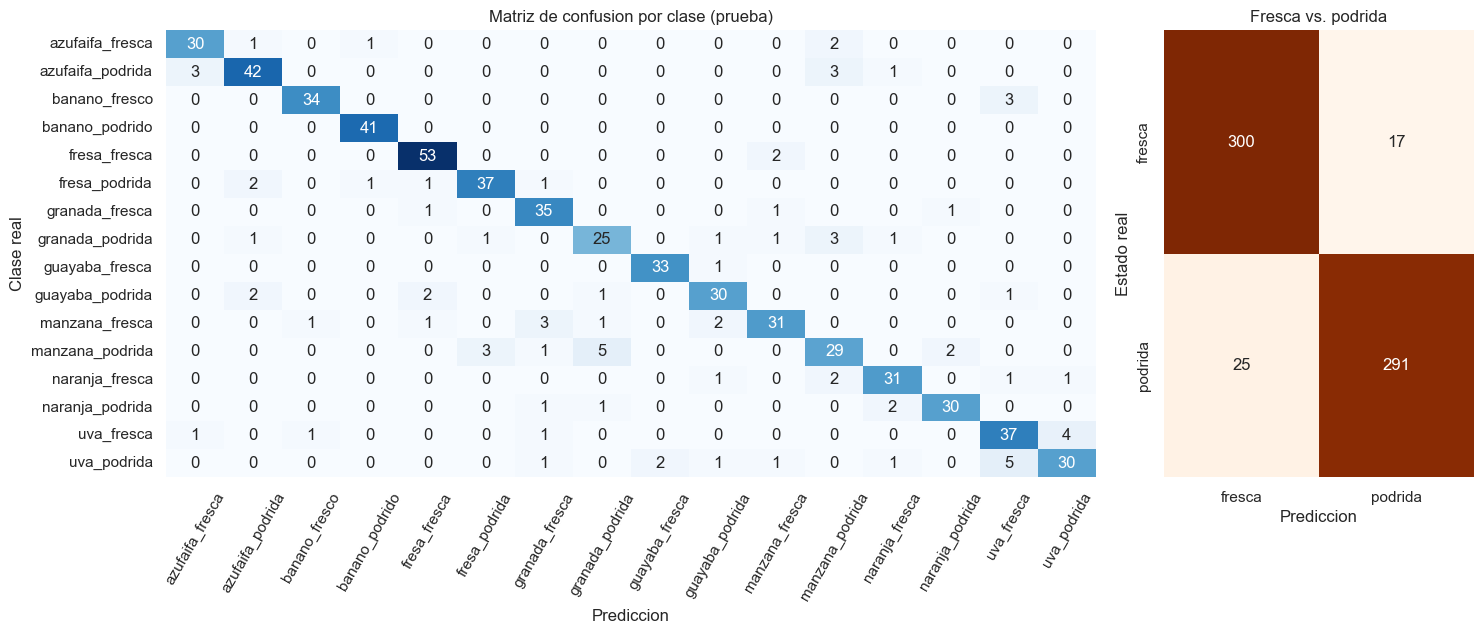

In [15]:
etiquetas = list(modelo.classes_)
fig, ejes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [3, 1]})
sns.heatmap(confusion_matrix(y_test, y_pred, labels=etiquetas), annot=True, fmt="d", cmap="Blues",
            xticklabels=etiquetas, yticklabels=etiquetas, ax=ejes[0], cbar=False)
ejes[0].set(title="Matriz de confusion por clase (prueba)", xlabel="Prediccion", ylabel="Clase real")
ejes[0].tick_params(axis="x", rotation=60)
sns.heatmap(confusion_matrix(estado_real, estado_pred, labels=["fresca", "podrida"]), annot=True, fmt="d",
            cmap="Oranges", xticklabels=["fresca", "podrida"], yticklabels=["fresca", "podrida"], ax=ejes[1],
            cbar=False)
ejes[1].set(title="Fresca vs. podrida", xlabel="Prediccion", ylabel="Estado real")
plt.tight_layout(); plt.show()

### 6.1 Confianza y errores

La app solo acepta una predicción si la probabilidad más alta supera un umbral; si no, pide revisar la fruta a mano. Se grafica la confianza de los aciertos y de los errores para elegir ese umbral, y se muestran fotos mal clasificadas.

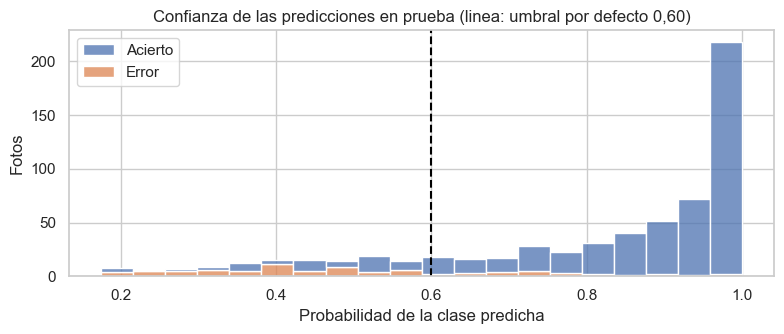

[INFO] Umbral 0.40: acepta 92% de las fotos, con 90.9% de acierto
[INFO] Umbral 0.50: acepta 87% de las fotos, con 93.3% de acierto
[INFO] Umbral 0.60: acepta 81% de las fotos, con 95.3% de acierto
[INFO] Umbral 0.70: acepta 74% de las fotos, con 96.4% de acierto
[INFO] Umbral 0.80: acepta 65% de las fotos, con 98.0% de acierto
[INFO] Fotos mal clasificadas: 85 de 633


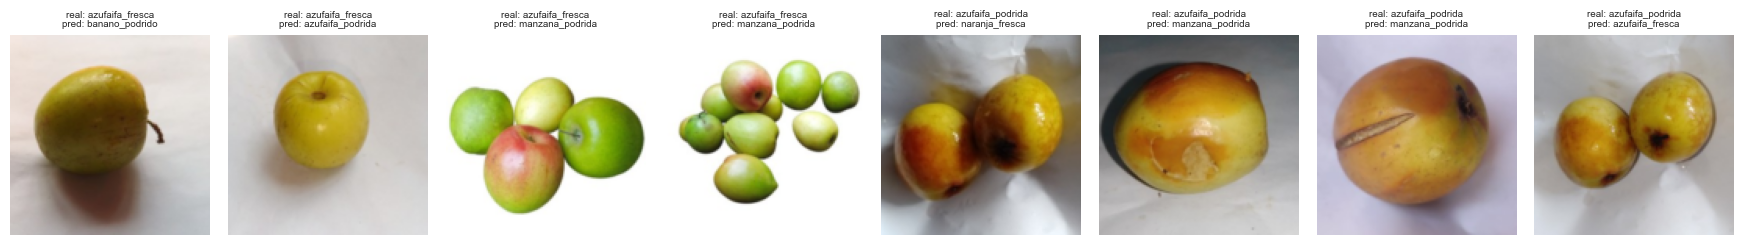

In [16]:
probas = modelo.predict_proba(X_test).max(axis=1)
acierto = y_pred == y_test
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(x=probas, hue=np.where(acierto, "Acierto", "Error"), bins=20, ax=ax, multiple="stack")
ax.axvline(0.6, color="black", ls="--")
ax.set(title="Confianza de las predicciones en prueba (linea: umbral por defecto 0,60)",
       xlabel="Probabilidad de la clase predicha", ylabel="Fotos")
plt.tight_layout(); plt.show()
for u in (0.4, 0.5, 0.6, 0.7, 0.8):
    aceptadas = probas >= u
    exactitud = acierto[aceptadas].mean() if aceptadas.any() else float("nan")
    print(f"[INFO] Umbral {u:.2f}: acepta {aceptadas.mean():.0%} de las fotos, con {exactitud:.1%} de acierto")

errores = np.where(~acierto)[0]
print(f"[INFO] Fotos mal clasificadas: {len(errores)} de {len(y_test)}")
if len(errores):
    n = min(8, len(errores))
    fig, ejes = plt.subplots(1, n, figsize=(2.2 * n, 2.8))
    for eje, i in zip(np.atleast_1d(ejes), errores[:n]):
        eje.imshow(normalizar_imagen(cargar_imagen(RAIZ / df_limpio.loc[idx_test[i], "ruta"])))
        eje.set_title(f"real: {y_test[i]}\npred: {y_pred[i]}", fontsize=7)
        eje.axis("off")
    plt.tight_layout(); plt.show()

## 7. Serialización del modelo

Se guarda el pipeline completo (escalador + SVM) en `models/modelo.pkl` con `joblib`, junto con `models/metadata.json` (clases, hiperparámetros, métricas y versiones). Luego se carga de nuevo y se verifica que predice lo mismo.

In [17]:
ruta_modelo = CARPETA_MODELOS / "modelo.pkl"
joblib.dump(modelo, ruta_modelo, compress=3)
metadatos = {
    "proyecto": "FrutaCheck: control de calidad de fruta (fresca o podrida)",
    "algoritmo": "Support Vector Machine (sklearn.svm.SVC)",
    "fecha_entrenamiento": datetime.now().isoformat(timespec="seconds"),
    "dataset": "Fresh and Rotten Fruits Dataset (Sultana, Jahan y Uddin, 2022), Mendeley Data, CC BY 4.0",
    "clases": etiquetas,
    "mejores_hiperparametros": {k.replace("svm__", ""): v for k, v in busqueda.best_params_.items()},
    "f1_macro_validacion_cruzada": round(float(busqueda.best_score_), 4),
    "metricas": {k: round(float(v), 4) for k, v in metricas.items()},
    "metricas_estado": {k: round(float(v), 4) for k, v in metricas_estado.items()},
    "accuracy_clasificador_base": round(float(acc_base), 4),
    "imagenes": {"total": int(len(df_limpio)), "entrenamiento": int(len(idx_train)), "prueba": int(len(idx_test))},
    "n_caracteristicas": int(X_total.shape[1]),
    "versiones": {"scikit-learn": sklearn.__version__, "numpy": np.__version__},
}
(CARPETA_MODELOS / "metadata.json").write_text(json.dumps(metadatos, indent=2, ensure_ascii=False), encoding="utf-8")

recargado = joblib.load(ruta_modelo)
iguales = bool((recargado.predict(X_test) == y_pred).all())
print(f"[OK] Modelo guardado en models/modelo.pkl ({ruta_modelo.stat().st_size / 1024:.0f} KB)")
print(f"[OK] El modelo recargado predice igual que el original: {iguales}")

[OK] Modelo guardado en models/modelo.pkl (34906 KB)
[OK] El modelo recargado predice igual que el original: True


## 8. Resumen del modelo

In [18]:
print("Estado del Modelo:")
print("- Modelo entrenado: SI")
print("- Archivo: models/modelo.pkl")
print(f"- Clases: {len(etiquetas)} ({', '.join(etiquetas)})")
print(f"- Imagenes: {len(df_limpio)} ({len(idx_train)} entrenamiento / {len(idx_test)} prueba)")
print(f"- Mejores hiperparametros: {metadatos['mejores_hiperparametros']}")
print(f"- Accuracy: {metricas['accuracy']:.1%}")
print(f"- Precision (macro): {metricas['precision_macro']:.1%}")
print(f"- Recall (macro): {metricas['recall_macro']:.1%}")
print(f"- F1 (macro): {metricas['f1_macro']:.1%}")
print(f"- Fresca vs. podrida: accuracy {metricas_estado['accuracy_estado']:.1%}, "
      f"recall de podridas {metricas_estado['recall_podrida']:.1%}")

Estado del Modelo:
- Modelo entrenado: SI
- Archivo: models/modelo.pkl
- Clases: 16 (azufaifa_fresca, azufaifa_podrida, banano_fresco, banano_podrido, fresa_fresca, fresa_podrida, granada_fresca, granada_podrida, guayaba_fresca, guayaba_podrida, manzana_fresca, manzana_podrida, naranja_fresca, naranja_podrida, uva_fresca, uva_podrida)
- Imagenes: 3193 (2560 entrenamiento / 633 prueba)
- Mejores hiperparametros: {'C': 100, 'class_weight': None, 'gamma': 0.0001, 'kernel': 'rbf'}
- Accuracy: 86.6%
- Precision (macro): 86.5%
- Recall (macro): 86.4%
- F1 (macro): 86.4%
- Fresca vs. podrida: accuracy 93.4%, recall de podridas 92.1%


## 9. Conclusiones

- El SVM con kernel RBF (C = 100, gamma = 0,0001), entrenado desde cero sobre características de color, textura y forma, alcanza **86,6 % de accuracy** y **86,4 % de F1 macro** en 16 clases (8 frutas × fresca/podrida), frente a 5,2 % del clasificador base. Supera con amplitud el mínimo de 70 %.
- Para la necesidad del negocio, la pregunta clave es **¿está podrida?** Ahí el modelo acierta el **93,4 %**, con **92,1 % de recall de podridas**: de cada 100 frutas podridas, detecta unas 92.
- Con el umbral de confianza por defecto (0,60) la app responde sola en el 81 % de las fotos, con 95,3 % de acierto; el resto lo manda a **revisar a mano**. Es mejor pedir revisión que dar por buena una fruta podrida.
- Las clases más difíciles son **manzana podrida** (F1 0,73), **granada podrida** (0,76) y **uva** (0,79-0,81): son pudriciones incipientes o racimos con fondo variado. Las mejores son **banano podrido** (0,98) y **guayaba fresca** (0,96).
- La división por grupos de casi duplicados (dHash) evita que fotos casi idénticas queden en entrenamiento y en prueba, así que las métricas son honestas. La F1 de validación cruzada (0,826) y la de prueba (0,864) son coherentes.
- **Limitaciones:** el modelo solo conoce estas 8 frutas; las fotos son de fruterías de Bangladés y la luz o el fondo de otra tienda pueden bajar el desempeño; una foto con varias frutas mezcladas confunde al modelo. Los mejores hiperparámetros quedaron en el borde de la rejilla (C más alto y gamma más bajo), así que una búsqueda más amplia podría mejorar un poco el resultado.
- **Trabajo futuro:** agregar fotos propias de tiendas colombianas con `src/capturar_fotos.py` (y frutas locales como mango, lulo o mora), un nivel intermedio "madura, vender pronto", y detección de varias frutas en una misma foto.

**Referencias**

[1] N. Sultana, M. Jahan, and M. S. Uddin, "Fresh and rotten fruits dataset for machine-based evaluation of fruit quality," Mendeley Data, V1, Apr. 2022, doi: 10.17632/bdd69gyhv8.1.

[2] Departamento Nacional de Planeación, "Pérdida y desperdicio de alimentos en Colombia: Estudio de la Dirección de Seguimiento y Evaluación de Políticas Públicas," DNP, Bogotá, Colombia, 2016.

[3] C. Cortes and V. Vapnik, "Support-vector networks," *Mach. Learn.*, vol. 20, no. 3, pp. 273–297, Sep. 1995, doi: 10.1007/BF00994018.

[4] T. Ojala, M. Pietikäinen, and T. Mäenpää, "Multiresolution gray-scale and rotation invariant texture classification with local binary patterns," *IEEE Trans. Pattern Anal. Mach. Intell.*, vol. 24, no. 7, pp. 971–987, Jul. 2002, doi: 10.1109/TPAMI.2002.1017623.

[5] N. Dalal and B. Triggs, "Histograms of oriented gradients for human detection," in *Proc. IEEE Comput. Soc. Conf. Comput. Vis. Pattern Recognit. (CVPR)*, San Diego, CA, USA, 2005, pp. 886–893, doi: 10.1109/CVPR.2005.177.

[6] F. Pedregosa *et al.*, "Scikit-learn: Machine learning in Python," *J. Mach. Learn. Res.*, vol. 12, pp. 2825–2830, 2011.